### Import libraries and load the CSV

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

# Load the results calculated in the cleaning step
file_path = 'Mid_cap/analysis/mid_cap_fund_results.csv'
mid_cap_results = pd.read_csv(file_path)

# Convert date columns to datetime
mid_cap_results['Start Date'] = pd.to_datetime(mid_cap_results['Start Date'])
mid_cap_results['End Date'] = pd.to_datetime(mid_cap_results['End Date'])

# Create folder for charts
os.makedirs('Mid_cap/analysis/charts', exist_ok=True)

print(mid_cap_results)

                             Fund Start Date  ... Maximum Drawdown  Sharpe Ratio
0                Axis Midcap Fund 2022-01-03  ...        -0.195165      0.581231
1             Bandhan Midcap Fund 2022-08-19  ...        -0.227126      0.928845
2          Edelweiss Mid Cap Fund 2022-01-03  ...        -0.181717      0.703249
3      Kotak Emerging Equity Fund 2022-01-03  ...        -0.242741      0.291873
4  Mahindra Manulife Mid Cap Fund 2022-01-03  ...        -0.209212      0.842859

[5 rows x 10 columns]


### Charts

### CAGR comparison

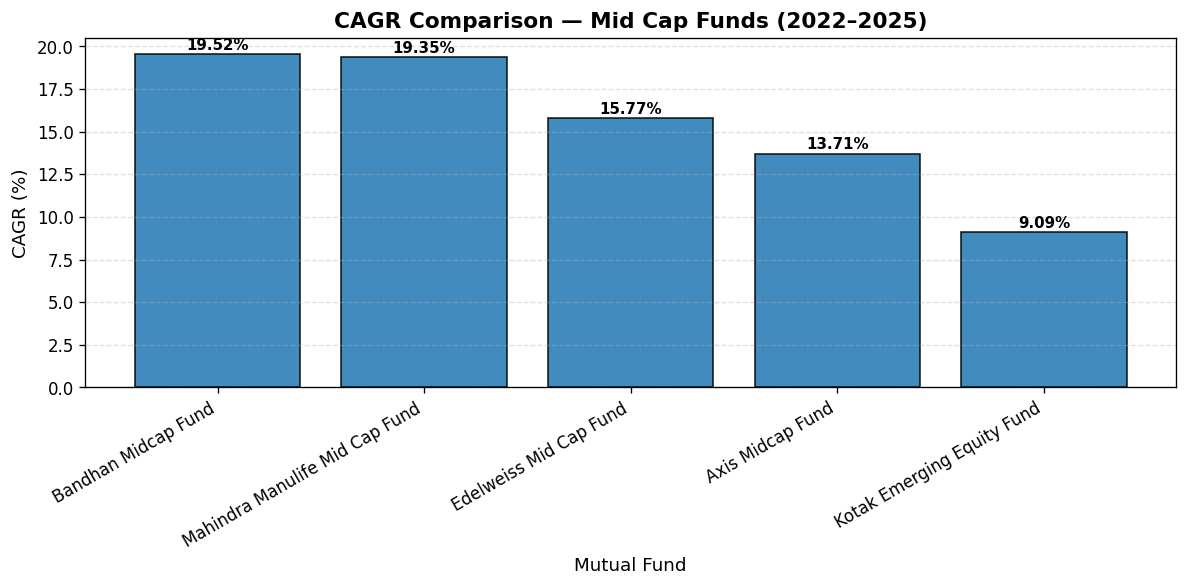

In [5]:
plot_data = mid_cap_results.sort_values('CAGR', ascending=False)

plt.figure(figsize=(10, 5))
plt.bar(plot_data['Fund'], plot_data['CAGR'] * 100, color='#1f77b4', edgecolor='black', alpha=0.85)
plt.title('CAGR Comparison — Mid Cap Funds (2022–2025)', fontsize=13, fontweight='bold')
plt.xlabel('Mutual Fund', fontsize=11)
plt.ylabel('CAGR (%)', fontsize=11)
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.4)
for i, v in enumerate(plot_data['CAGR'] * 100):
    plt.text(i, v + 0.3, f'{v:.2f}%', ha='center', fontweight='bold', fontsize=9)
plt.tight_layout()

plt.savefig('Mid_cap/analysis/charts/mid_cap_cagr.png', dpi=300, bbox_inches='tight')
plt.show()

### Annualized volatility

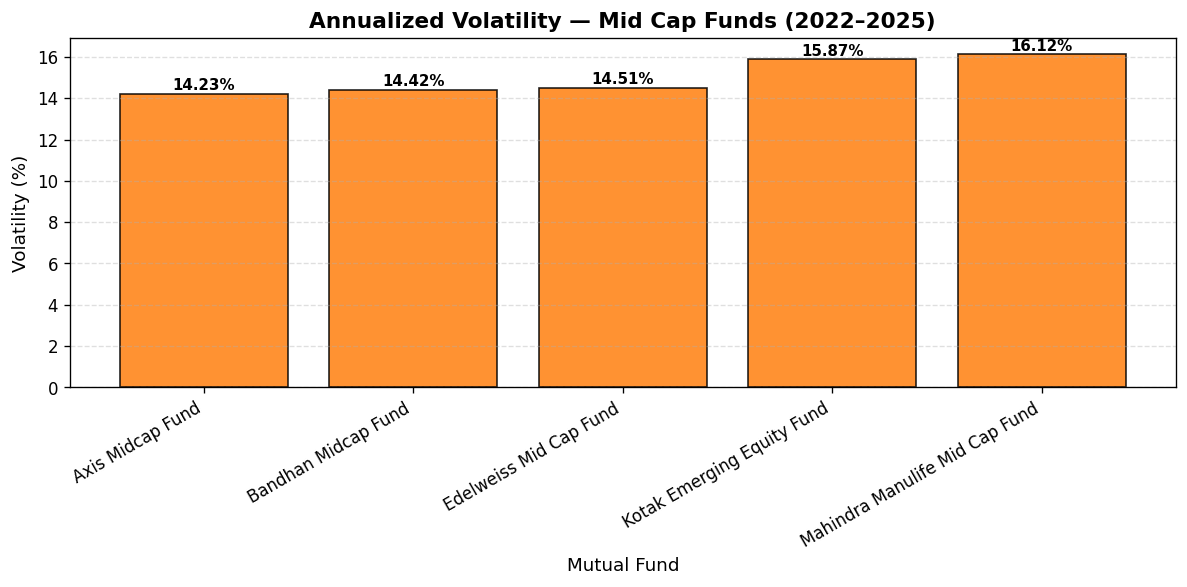

In [7]:
plot_data = mid_cap_results.sort_values('Volatility', ascending=True)

plt.figure(figsize=(10, 5))
plt.bar(plot_data['Fund'], plot_data['Volatility'] * 100, color='#ff7f0e', edgecolor='black', alpha=0.85)
plt.title('Annualized Volatility — Mid Cap Funds (2022–2025)', fontsize=13, fontweight='bold')
plt.xlabel('Mutual Fund', fontsize=11)
plt.ylabel('Volatility (%)', fontsize=11)
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.4)
for i, v in enumerate(plot_data['Volatility'] * 100):
    plt.text(i, v + 0.2, f'{v:.2f}%', ha='center', fontweight='bold', fontsize=9)
plt.tight_layout()

plt.savefig('Mid_cap/analysis/charts/mid_cap_volatility.png', dpi=300, bbox_inches='tight')
plt.show()

### Maximum drawdown

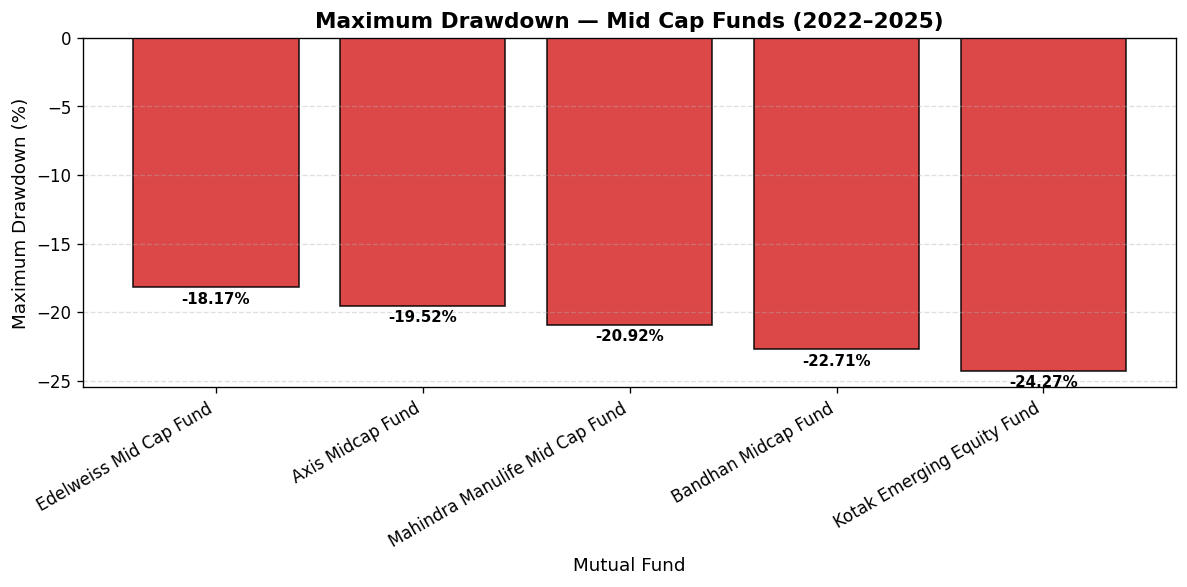

In [9]:
plot_data = mid_cap_results.sort_values('Maximum Drawdown', ascending=False)

plt.figure(figsize=(10, 5))
plt.bar(plot_data['Fund'], plot_data['Maximum Drawdown'] * 100, color='#d62728', edgecolor='black', alpha=0.85)
plt.title('Maximum Drawdown — Mid Cap Funds (2022–2025)', fontsize=13, fontweight='bold')
plt.xlabel('Mutual Fund', fontsize=11)
plt.ylabel('Maximum Drawdown (%)', fontsize=11)
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.4)
for i, v in enumerate(plot_data['Maximum Drawdown'] * 100):
    plt.text(i, v - 1.2, f'{v:.2f}%', ha='center', fontweight='bold', fontsize=9)
plt.tight_layout()

plt.savefig('Mid_cap/analysis/charts/mid_cap_max_drawdown.png', dpi=300, bbox_inches='tight')
plt.show()

### Sharpe ratio

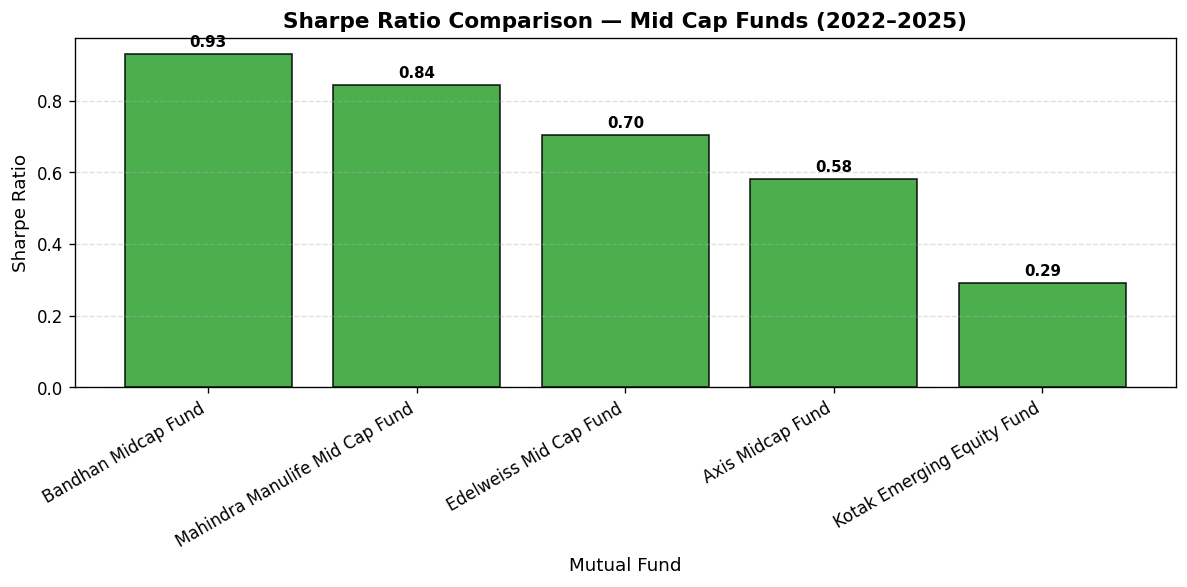

In [11]:
plot_data = mid_cap_results.sort_values('Sharpe Ratio', ascending=False)

plt.figure(figsize=(10, 5))
plt.bar(plot_data['Fund'], plot_data['Sharpe Ratio'], color='#2ca02c', edgecolor='black', alpha=0.85)
plt.title('Sharpe Ratio Comparison — Mid Cap Funds (2022–2025)', fontsize=13, fontweight='bold')
plt.xlabel('Mutual Fund', fontsize=11)
plt.ylabel('Sharpe Ratio', fontsize=11)
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.4)
for i, v in enumerate(plot_data['Sharpe Ratio']):
    plt.text(i, v + 0.02, f'{v:.2f}', ha='center', fontweight='bold', fontsize=9)
plt.tight_layout()

plt.savefig('Mid_cap/analysis/charts/mid_cap_sharpe.png', dpi=300, bbox_inches='tight')
plt.show()

### Risk vs. return scatter plot

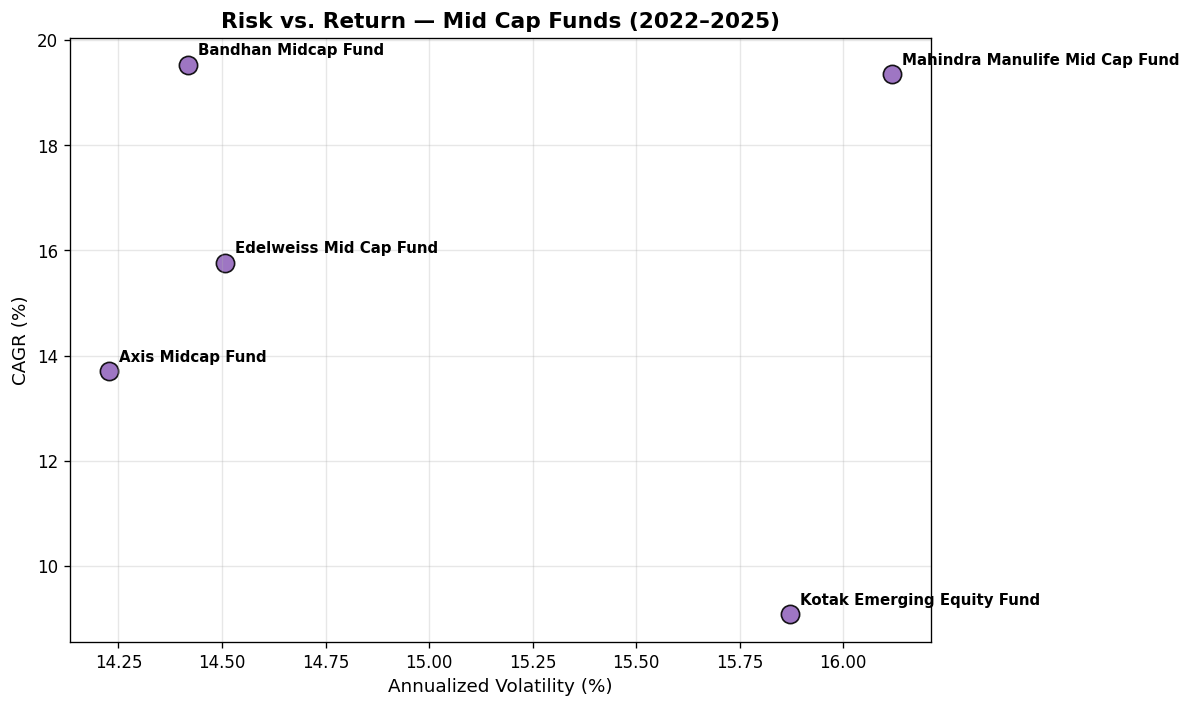

In [13]:
plt.figure(figsize=(10, 6))

plt.scatter(
    mid_cap_results['Volatility'] * 100,
    mid_cap_results['CAGR'] * 100,
    s=120,
    c='#9467bd',
    edgecolor='black',
    alpha=0.9
)

for _, row in mid_cap_results.iterrows():
    plt.annotate(
        row['Fund'],
        (
            row['Volatility'] * 100,
            row['CAGR'] * 100
        ),
        xytext=(6, 6),
        textcoords='offset points',
        fontsize=9,
        fontweight='semibold'
    )

plt.title('Risk vs. Return — Mid Cap Funds (2022–2025)', fontsize=13, fontweight='bold')
plt.xlabel('Annualized Volatility (%)', fontsize=11)
plt.ylabel('CAGR (%)', fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig('Mid_cap/analysis/charts/mid_cap_risk_return.png', dpi=300, bbox_inches='tight')
plt.show()

### Performance metrics heatmap

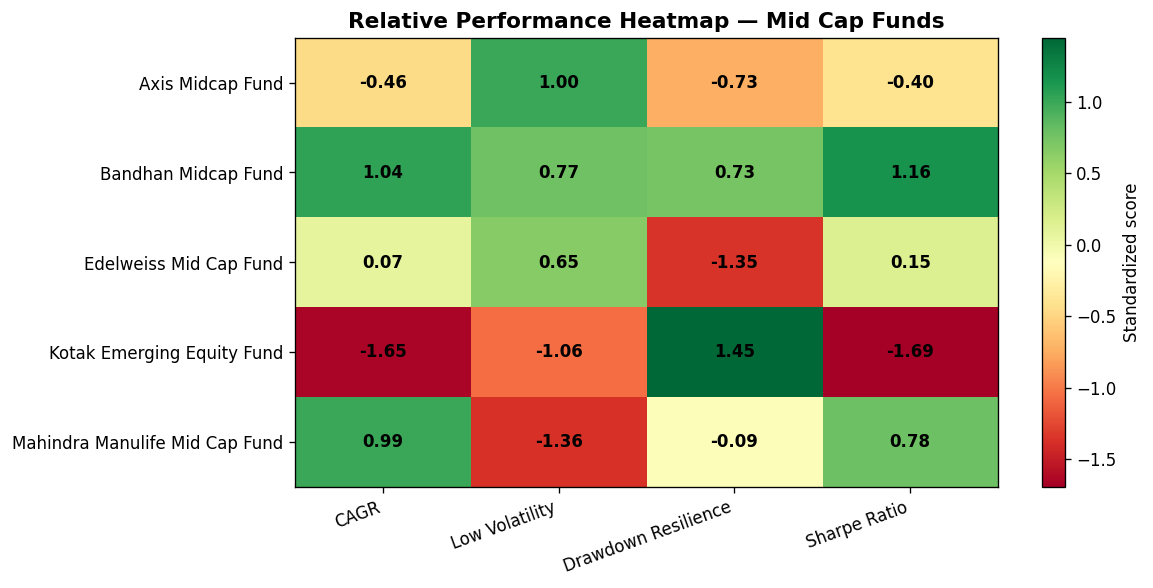

In [15]:
metrics = mid_cap_results.set_index('Fund')[
    ['CAGR', 'Volatility', 'Maximum Drawdown', 'Sharpe Ratio']
].copy()

# Higher values should represent better outcomes for every metric
metrics['Maximum Drawdown'] = -metrics['Maximum Drawdown']
metrics['Volatility'] = -metrics['Volatility']

# Standardize each metric across the funds
scores = (metrics - metrics.mean()) / metrics.std(ddof=0)

plt.figure(figsize=(10, 5))
image = plt.imshow(scores, aspect='auto', cmap='RdYlGn')

plt.xticks(
    range(len(scores.columns)),
    ['CAGR', 'Low Volatility', 'Drawdown Resilience', 'Sharpe Ratio'],
    rotation=20,
    ha='right',
    fontsize=10
)
plt.yticks(range(len(scores.index)), scores.index, fontsize=10)

for i in range(scores.shape[0]):
    for j in range(scores.shape[1]):
        plt.text(
            j, i, f'{scores.iloc[i, j]:.2f}',
            ha='center', va='center', fontweight='bold'
        )

plt.colorbar(image, label='Standardized score')
plt.title('Relative Performance Heatmap — Mid Cap Funds', fontsize=13, fontweight='bold')
plt.tight_layout()

plt.savefig('Mid_cap/analysis/charts/mid_cap_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

### Radar chart

Radar chart saved successfully.


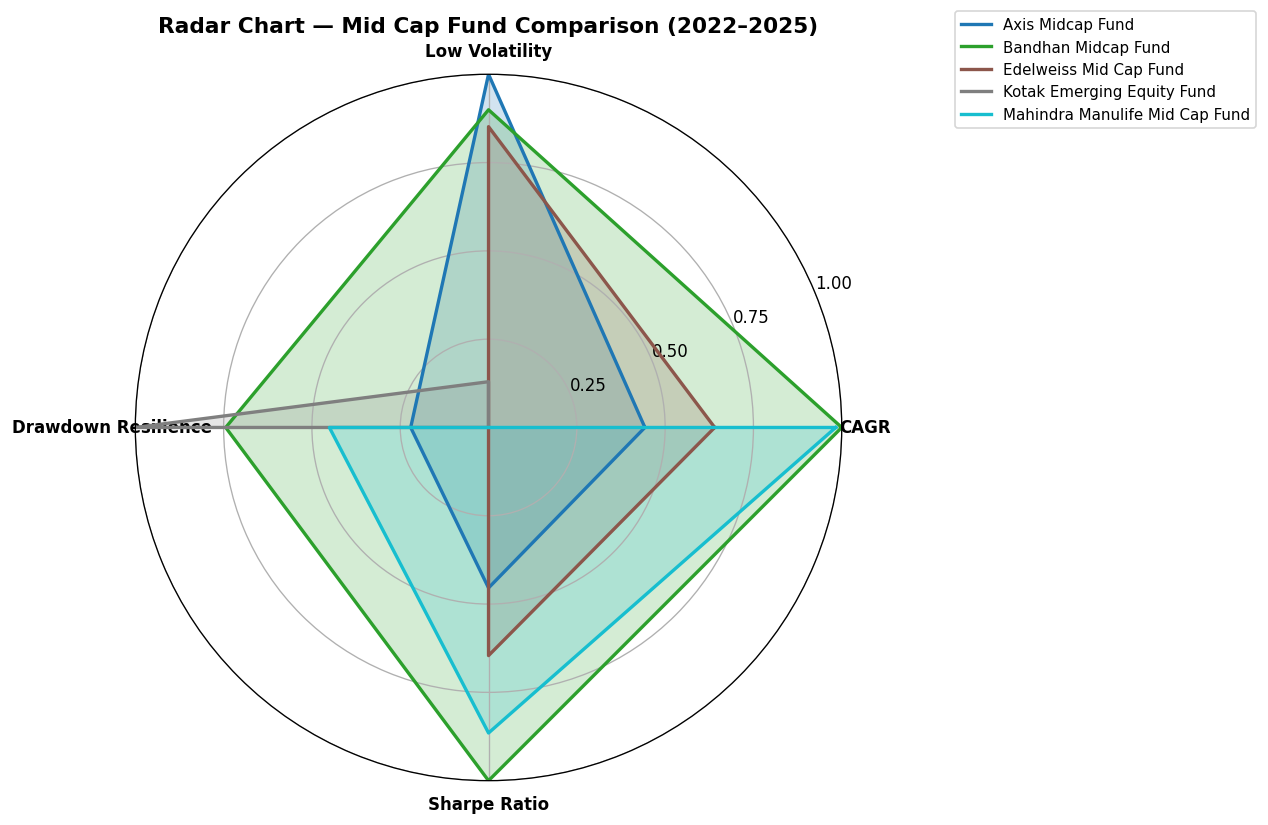

In [17]:
metrics_radar = mid_cap_results.set_index('Fund')[
    ['CAGR', 'Volatility', 'Maximum Drawdown', 'Sharpe Ratio']
].copy()

metrics_radar['Volatility'] = -metrics_radar['Volatility']
metrics_radar['Maximum Drawdown'] = -metrics_radar['Maximum Drawdown']

min_values = metrics_radar.min()
max_values = metrics_radar.max()

normalized = (metrics_radar - min_values) / (max_values - min_values)
normalized = normalized.fillna(0)

categories = ['CAGR', 'Low Volatility', 'Drawdown Resilience', 'Sharpe Ratio']
num_vars = len(categories)

angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(10, 9), subplot_kw={'polar': True})
colors = plt.cm.tab10(np.linspace(0, 1, len(normalized)))

for (fund_name, row), color in zip(normalized.iterrows(), colors):
    values = row.tolist()
    values += values[:1]
    ax.plot(angles, values, linewidth=2, color=color, label=fund_name)
    ax.fill(angles, values, color=color, alpha=0.20)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=10, fontweight='semibold')
ax.set_ylim(0, 1)
ax.set_yticks([0.25, 0.50, 0.75, 1.00])
ax.set_yticklabels(['0.25', '0.50', '0.75', '1.00'])

ax.set_title('Radar Chart — Mid Cap Fund Comparison (2022–2025)', pad=25, fontsize=13, fontweight='bold')
ax.legend(loc='upper left', bbox_to_anchor=(1.15, 1.10), fontsize=9)
plt.tight_layout()

plt.savefig('Mid_cap/analysis/charts/mid_cap_radar.png', dpi=300, bbox_inches='tight')
plt.show()
print('Radar chart saved successfully.')